# First Light — database & ledger research (VPS `trading_production`)

**Data pulled:** 2026-10-21, read-only (`default_transaction_read_only=on`) from the production Postgres on the VPS. No auth/user/bot tables were exported. CSVs live in `data/` (git-ignored).

**Questions**
1. What is actually in the database, and how much of it is usable for research?
2. What does the live signal ledger say, once censoring (open trades) and clustering (same-day trades) are handled honestly?
3. Do the 9-year backtest findings replicate in the live ledger?
4. What do the forward labels, the paper tracker and the market-context tables add?
5. What can we *not* conclude yet?

R convention: R = |entry − stop| = 2×ATR. target1 = +1R, stop = −1R, expiry = mark-to-market at bar 20. Break-even win rate = 50%.

> **Correction (2026-10-21, see `EXECUTION_RULE_PARITY_AUDIT.md`).** The backtest figures in this notebook use the dataset's `r_single`, which is the **3R-target** exit with close entry, no gaps and no cost. The live ledger exits at the **first** target (+1R). Section 5 and the summary therefore compare two different exit rules. On the live rule, the 2021-09 → 2026-09 history averages +0.006 R (longs +0.062, shorts −0.058) before execution effects, and −0.036 R once executed (next open, gaps, 10 bps). The censoring, grade, replication and funnel findings are unaffected.

In [1]:
import json, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")
pd.set_option("display.width", 200, "display.max_columns", 40, "display.float_format", lambda x: f"{x:,.3f}")
plt.rcParams.update({"figure.figsize": (9, 3.6), "axes.grid": True, "grid.alpha": .25})
D = "data/"
rng = np.random.default_rng(7)

def boot_mean(df, col="outcome_r", cluster="signal_date", n=2000):
    """Mean of `col` with a 95% CI from a cluster bootstrap (resample whole days; trades on one day are correlated)."""
    if len(df) == 0: return (np.nan, np.nan, np.nan, 0)
    g = {k: v[col].to_numpy() for k, v in df.groupby(cluster)}
    keys = list(g); m = df[col].mean()
    sums = np.array([g[k].sum() for k in keys]); cnt = np.array([len(g[k]) for k in keys])
    idx = rng.integers(0, len(keys), (n, len(keys)))
    b = sums[idx].sum(1) / cnt[idx].sum(1)
    lo, hi = np.percentile(b, [2.5, 97.5])
    return (m, lo, hi, len(df))

def table_by(df, col, **kw):
    rows = []
    for k, g in df.groupby(col):
        m, lo, hi, n = boot_mean(g, **kw)
        rows.append({col: k, "n": n, "win%": g["win"].mean() * 100, "avgR": m, "ci_lo": lo, "ci_hi": hi, "avg_bars": g["bars_held"].mean()})
    return pd.DataFrame(rows).set_index(col)

RESOLVED = ["stopped", "target1", "target2", "target3", "expired"]

## 1. What is in the database

In [2]:
sizes = pd.read_csv(D + "table_sizes.csv"); sizes.columns = ["table_name", "approx_rows"]
domains = {
 "Prices & indicators": ["stock_prices","technical_indicators","weekly_technical_indicators","monthly_technical_indicators","market_index_prices","price_discontinuities","price_discontinuity_scan","inactive_symbols","companies"],
 "Fundamentals & events": ["daily_fundamentals","quarterly_fundamentals","earnings_calendar","news_items","news_fetched","market_event","market_event_revision","catalyst_classification","source_observation","source_poll"],
 "Legacy screener / ML": ["breakouts","momentum_scores","enhanced_ml_training_data","ml_predictions","ml_models","ml_prediction_outcomes","ml_performance_metrics","digest_stocks","digest_runs","alerts"],
 "Strategy ledger & research capture": ["strategies","signal_ledger","candidate_observation","feature_snapshot","candidate_capture_run","feature_set_registry","research_capture_activation","funnel_events","forward_return_label","ml_breakout_dataset_v2","dataset_manifest","experiment_registration","experiment_result"],
 "Paper tracker & variants": ["strategy_variant","paper_session","paper_observation","paper_event"],
 "Market intelligence": ["market_snapshot","universe_snapshot","stock_relative_strength","sector_observation","sector_snapshot","sector_performance_daily","sector_poll","sector_reconstruction"],
}
s = sizes.set_index("table_name").approx_rows
out = []
for dom, ts in domains.items():
    for t in ts:
        if t in s.index: out.append((dom, t, int(s[t])))
inv = pd.DataFrame(out, columns=["domain","table","rows"])
print(inv.groupby("domain").rows.agg(["count","sum"]).rename(columns={"count":"tables","sum":"rows"}).to_string())
print("\nEmpty tables that are *designed* to hold research (nothing feeds them yet):")
print(inv[(inv.rows==0)].table.tolist())

                                    tables      rows
domain                                              
Fundamentals & events                   10    650667
Legacy screener / ML                    10    431111
Market intelligence                      8     93587
Paper tracker & variants                 4     14367
Prices & indicators                      9  13276546
Strategy ledger & research capture      13    656761

Empty tables that are *designed* to hold research (nothing feeds them yet):
['market_event', 'market_event_revision', 'catalyst_classification', 'source_observation', 'source_poll', 'ml_prediction_outcomes', 'ml_performance_metrics', 'alerts', 'dataset_manifest', 'experiment_registration', 'experiment_result', 'sector_reconstruction']


In [3]:
px = pd.read_csv(D + "breakouts_v2.csv", parse_dates=["date"])
print("backtest dataset (ml_breakout_dataset_v2):", len(px), "rows,", px.symbol.nunique(), "symbols,", px.date.min().date(), "->", px.date.max().date())
print("matured (has r_single):", px.r_single.notna().sum(), "| not yet matured:", px.r_single.isna().sum())
print("missing share per feature:"); print((px.isna().mean().sort_values(ascending=False).head(6)*100).round(2).to_string())

backtest dataset (ml_breakout_dataset_v2): 603597 rows, 3040 symbols, 2018-01-02 -> 2026-10-20
matured (has r_single): 595541 | not yet matured: 8056
missing share per feature:
dist_sma200_pct   1.930
tp3_hit           1.330
plan_r            1.330
r_single          1.330
stopped           1.330
mae_r             1.330


## 2. The live ledger — headline (must reproduce the dashboard)

In [4]:
L = pd.read_csv(D + "signal_ledger.csv", parse_dates=["signal_date", "resolved_date", "last_evaluated_date"])
L["win"] = L.status.str.startswith("target")
L["res"] = L.status.isin(RESOLVED)
L["risk_pct"] = (L.entry_price - L.stop_price).abs() / L.entry_price * 100
L["dir"] = L.direction.map({1: "bullish", -1: "bearish"})
sessions = np.sort(L.signal_date.unique())
L["age_sessions"] = L.signal_date.map({d: len(sessions) - 1 - i for i, d in enumerate(sessions)})   # sessions since the signal (approx)
R = L[L.res].copy()
head = L.groupby("dir").agg(signals=("id","size"), open=("status", lambda s: (s=="open").sum()), resolved=("res","sum"))
head["win%"] = R.groupby("dir").win.mean()*100
head["avgR"] = R.groupby("dir").outcome_r.mean()
head["sumR"] = R.groupby("dir").outcome_r.sum()
gross_w = R[R.outcome_r>0].groupby("dir").outcome_r.sum(); gross_l = -R[R.outcome_r<0].groupby("dir").outcome_r.sum()
head["profit_factor"] = gross_w/gross_l
print(head.to_string())
print("\nALL resolved:", len(R), "avgR=%.3f" % R.outcome_r.mean(), "sumR=%.0f" % R.outcome_r.sum(), "| signals:", len(L), "| first/last signal:", L.signal_date.min().date(), L.signal_date.max().date())
m, lo, hi, n = boot_mean(R); print("cluster-bootstrap 95%% CI for avgR: %.3f [%.3f, %.3f]  (days resampled: %d)" % (m, lo, hi, R.signal_date.nunique()))
for d, g in R.groupby("dir"):
    m, lo, hi, n = boot_mean(g); print(f"  {d}: {m:+.3f} [{lo:+.3f}, {hi:+.3f}] n={n}")

         signals  open  resolved   win%  avgR   sumR  profit_factor
dir                                                                
bearish     1817   919       898 53.675 0.079 71.000          1.171
bullish     1047   537       510 50.784 0.037 19.000          1.076

ALL resolved: 1408 avgR=0.064 sumR=90 | signals: 2864 | first/last signal: 2026-09-28 2026-10-20
cluster-bootstrap 95% CI for avgR: 0.064 [-0.071, 0.309]  (days resampled: 14)
  bearish: +0.079 [-0.031, +0.333] n=898
  bullish: +0.037 [-0.205, +0.363] n=510


**Read-out.** The table must match the dashboard (1,408 resolved; +71 R bearish, +19 R bullish). The point of the bootstrap is that signals from the same day share one market move, so the effective sample is closer to the number of *days* than the number of trades.

## 3. Censoring: how much of the ledger is still unknown?

               n  resolved  avg_age
signal_date                        
2026-09-28   490    78.800       14
2026-10-01   363    72.500       13
2026-10-02   169    82.800       12
2026-10-05   126    69.000       11
2026-10-06    99    63.600       10
2026-10-07   156    56.400        9
2026-10-08   102    66.700        8
2026-10-09   109    57.800        7
2026-10-12   134    53.700        6
2026-10-13   243    41.600        5
2026-10-14   211    19.900        4
2026-10-15   223     9.400        3
2026-10-16   205     4.900        2
2026-10-19   112     3.600        1
2026-10-20   122     0.000        0


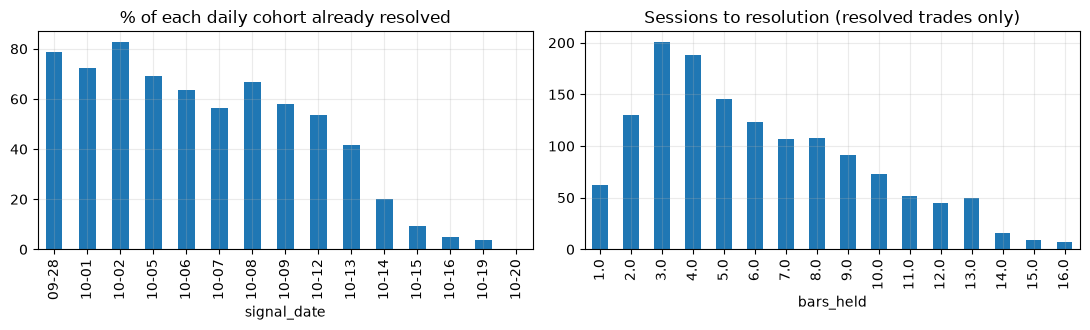

Median sessions to resolve: 5 | 90th pct: 11 | share resolved in <=3 sessions: 28%


In [5]:
coh = L.groupby("signal_date").agg(n=("id","size"), resolved=("res","mean"), avg_age=("age_sessions","first"))
print(coh.assign(resolved=lambda d: d.resolved*100).round(1).to_string())
fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
coh.resolved.mul(100).plot.bar(ax=ax[0], title="% of each daily cohort already resolved"); ax[0].set_xticklabels([d.strftime("%m-%d") for d in coh.index])
R.bars_held.value_counts().sort_index().plot.bar(ax=ax[1], title="Sessions to resolution (resolved trades only)")
plt.tight_layout(); plt.show()
print("Median sessions to resolve: %d | 90th pct: %d | share resolved in <=3 sessions: %.0f%%" % (R.bars_held.median(), R.bars_held.quantile(.9), (R.bars_held<=3).mean()*100))

Because most trades resolve in 3–10 sessions, a cohort needs about **10+ sessions** before it is mostly resolved and **20 sessions** before every trade is final (the expiry bar). Anything younger is *right-censored*: the quick resolvers are in the table and the slow ones are not. If quick resolvers differ systematically (cheap, volatile, wide stop) any cut by price, grade or sector is biased until the cohorts mature.

**Bounds that need no assumption** (Manski): put every open trade at −1 R (worst) or +1 R (best).

In [6]:
op = L[(L.status=="open")]
n_all = len(L)
lo_b = (R.outcome_r.sum() - len(op)) / n_all
hi_b = (R.outcome_r.sum() + len(op)) / n_all
print(f"Resolved + open as worst case: {lo_b:+.3f} R/signal | best case: {hi_b:+.3f} R/signal | open signals: {len(op)} ({len(op)/n_all:.0%})")
print("Open signals' current adverse excursion (MAE, in R): median %.2f, share already past 0.8R: %.1f%%" % (op.mae_r.median(), (op.mae_r>.8).mean()*100))
# oldest cohorts only (>= 12 sessions old): the least censored slice we have
old = L[L.age_sessions >= 12]
print(f"\nOldest cohorts (age>=12 sessions): n={len(old)}, resolved={old.res.mean():.0%}")
ro = old[old.res]; m, lo, hi, n = boot_mean(ro); print(f"  avgR={m:+.3f} [{lo:+.3f}, {hi:+.3f}], win%={ro.win.mean()*100:.1f}")
for d, g in ro.groupby("dir"):
    m, lo, hi, n = boot_mean(g); print(f"  {d}: {m:+.3f} [{lo:+.3f}, {hi:+.3f}] n={n}")

Resolved + open as worst case: -0.477 R/signal | best case: +0.540 R/signal | open signals: 1456 (51%)
Open signals' current adverse excursion (MAE, in R): median 0.44, share already past 0.8R: 12.6%

Oldest cohorts (age>=12 sessions): n=1022, resolved=77%
  avgR=-0.134 [-0.329, -0.049], win%=42.7
  bearish: -0.051 [-0.104, +0.042] n=573
  bullish: -0.356 [-0.522, -0.227] n=216


### Censoring-corrected view: what had happened by session *k*, for every signal old enough to be judged at *k*
For each k, take **all** signals with at least k sessions of history (resolved *and* open) and credit each with the R it had locked in by session k (open = 0). This compares like with like across cohorts and does not drop slow trades.

In [7]:
rows = []
for k in (2, 3, 5, 8, 10):
    d = L[L.age_sessions >= k].copy()
    d["locked"] = np.where(d.res & (d.bars_held <= k), d.outcome_r, 0.0)
    d["won"] = d.res & (d.bars_held <= k) & d.win; d["lost"] = d.res & (d.bars_held <= k) & ~d.win
    for dn, g in [("all", d)] + list(d.groupby("dir")):
        m_, lo_, hi_, n_ = boot_mean(g, col="locked")
        rows.append({"k": k, "dir": dn, "n": n_, "won%": g.won.mean()*100, "lost%": g.lost.mean()*100, "still_open%": 100-(g.won.mean()+g.lost.mean())*100, "locked_R": m_, "ci_lo": lo_, "ci_hi": hi_})
print(pd.DataFrame(rows).set_index(["k","dir"]).round(3).to_string())

               n   won%  lost%  still_open%  locked_R  ci_lo  ci_hi
k  dir                                                             
2  all      2630  3.992  3.156       92.852     0.012 -0.006  0.031
   bearish  1706  3.107  2.521       94.373     0.008 -0.014  0.031
   bullish   924  5.628  4.329       90.043     0.021 -0.017  0.056
3  all      2425  9.567  6.062       84.371     0.040  0.007  0.084
   bearish  1578  7.478  4.816       87.706     0.029 -0.002  0.076
   bullish   847 13.459  8.383       78.158     0.060 -0.005  0.115
5  all      1991 18.684 13.963       67.353     0.053 -0.012  0.142
   bearish  1350 16.519 10.519       72.963     0.062  0.014  0.158
   bullish   641 23.245 21.217       55.538     0.033 -0.099  0.166
8  all      1505 23.987 25.980       50.033    -0.014 -0.085  0.117
   bearish  1080 23.519 20.370       56.111     0.035 -0.019  0.185
   bullish   425 25.176 40.235       34.588    -0.139 -0.285  0.083
10 all      1247 25.581 35.365       39.054    -

               n  locked5  resolved_by_5
signal_date                             
2026-09-28   490   -0.024         24.082
2026-10-01   363    0.017         25.895
2026-10-02   169   -0.166         35.503
2026-10-05   126   -0.024         37.302
2026-10-06    99   -0.020         23.232
2026-10-07   156    0.096         28.846
2026-10-08   102    0.314         42.157
2026-10-09   109    0.138         48.624
2026-10-12   134    0.313         49.254
2026-10-13   243    0.165         41.564


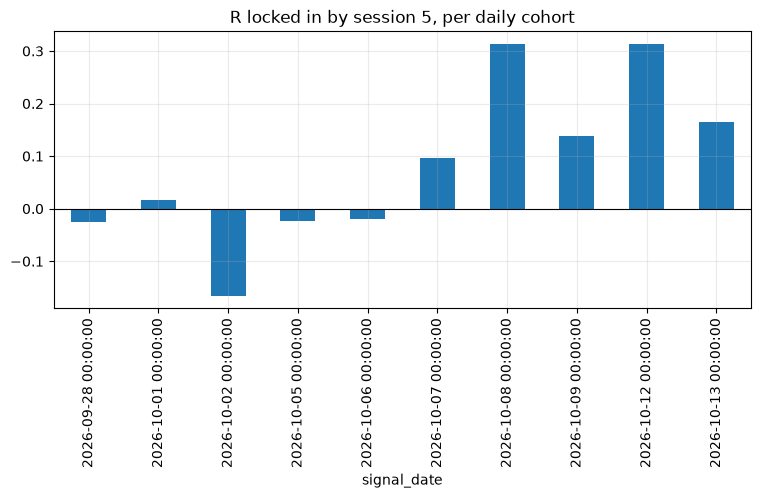

In [8]:
# the same, cohort by cohort: R locked in within 5 sessions (only cohorts old enough)
d = L[L.age_sessions >= 5].copy(); d["locked5"] = np.where(d.res & (d.bars_held <= 5), d.outcome_r, 0.0)
c5 = d.groupby("signal_date").agg(n=("id","size"), locked5=("locked5","mean"), resolved_by_5=("locked5", lambda s: (s!=0).mean()*100))
print(c5.round(3).to_string()); c5.locked5.plot.bar(title="R locked in by session 5, per daily cohort"); plt.axhline(0,c="k",lw=.8); plt.show()

In [9]:
# Same cohorts, followed over time: is the decline from k=5 to k=10 real, or just a change of cohort mix?
fixed = L[L.age_sessions >= 10]
rows = []
for k in (2, 3, 5, 8, 10, 12):
    d = fixed[fixed.age_sessions >= k].copy() if k <= 10 else fixed[fixed.age_sessions >= 12]
    d["locked"] = np.where(d.res & (d.bars_held <= k), d.outcome_r, 0.0)
    m_, lo_, hi_, n_ = boot_mean(d, col="locked")
    rows.append({"k": k, "n": n_, "cohort_days": d.signal_date.nunique(), "locked_R": m_, "ci_lo": lo_, "ci_hi": hi_, "still_open%": (~(d.res & (d.bars_held<=k))).mean()*100})
print("Fixed set = signals with age >= 10 sessions (cohorts 09-28 .. 10-06)")
print(pd.DataFrame(rows).set_index("k").round(3).to_string())

Fixed set = signals with age >= 10 sessions (cohorts 09-28 .. 10-06)
       n  cohort_days  locked_R  ci_lo  ci_hi  still_open%
k                                                         
2   1247            5     0.007 -0.026  0.026       93.665
3   1247            5    -0.001 -0.034  0.014       85.565
5   1247            5    -0.031 -0.095  0.005       72.574
8   1247            5    -0.069 -0.126 -0.030       51.724
10  1247            5    -0.091 -0.172 -0.020       39.054
12  1022            3    -0.071 -0.272 -0.028       30.822


**Why this matters.** The headline counts only trades that have finished. Early finishers differ from late finishers; compare the oldest, nearly-complete cohorts with the average of everything before reading the headline as an expectancy.

## 4. Where is the result coming from? (and how far to trust each cut)

Every cut below also prints the **share of that bucket that is already resolved** — if a bucket looks great *and* resolves much faster than the rest, the number is partly an artefact of censoring.

In [10]:
def cut(col, bins=None, labels=None, df=R, all_=L):
    d = df.copy(); a = all_.copy()
    if bins is not None:
        d[col+"_b"] = pd.cut(d[col], bins, labels=labels); a[col+"_b"] = pd.cut(a[col], bins, labels=labels); c = col+"_b"
    else: c = col
    t = table_by(d, c)
    t["resolved%"] = a.groupby(c).res.mean()*100
    return t
print("--- by quality grade"); print(cut("quality_grade").to_string())
print("\n--- by entry price"); print(cut("entry_price", [0,5,10,20,50,100,1e6], ["<5","5-10","10-20","20-50","50-100",">100"]).to_string())
print("\n--- by stop distance (% of price)"); print(cut("risk_pct", [0,4,6,8,11,100], ["<4","4-6","6-8","8-11",">11"]).to_string())
print("\n--- by sector"); print(cut("sector").sort_values("n", ascending=False).to_string())

--- by quality grade
                 n   win%   avgR  ci_lo  ci_hi  avg_bars  resolved%
quality_grade                                                      
A              259 40.541 -0.181 -0.321  0.080     6.548     44.732
B              251 44.223 -0.112 -0.270  0.235     6.502     47.092
C              229 52.838  0.061 -0.154  0.451     5.655     51.577
D              231 45.887 -0.069 -0.258  0.331     5.939     50.881
F              438 68.037  0.381  0.228  0.506     5.811     51.288

--- by entry price
                 n   win%   avgR  ci_lo  ci_hi  avg_bars  resolved%
entry_price_b                                                      
<5             177 73.446  0.492  0.386  0.635     5.960     54.799
5-10           171 67.251  0.351  0.172  0.643     6.556     49.565
10-20          230 59.130  0.196  0.025  0.492     6.004     47.817
20-50          260 51.154  0.038 -0.128  0.314     6.423     44.674
50-100         228 41.228 -0.167 -0.322  0.117     6.061     49.673
>100   

                          n   win%   avgR  ci_lo  ci_hi  avg_bars  resolved%
sector                                                                      
Technology              289 41.176 -0.159 -0.423  0.326     5.789     56.335
Healthcare              243 55.967  0.132 -0.210  0.410     5.704     47.276
Financial Services      202 51.980  0.045 -0.127  0.413     6.530     48.558
Industrials             187 57.219  0.150 -0.129  0.536     5.968     47.949
Consumer Cyclical       117 64.103  0.299  0.031  0.641     5.769     42.545
Real Estate             100 64.000  0.280 -0.049  0.659     6.650     48.544
Consumer Defensive       77 49.351 -0.013 -0.426  0.674     5.766     58.779
Communication Services   56 41.071 -0.107 -0.366  0.226     6.179     50.450
Basic Materials          55 65.455  0.309 -0.267  0.564     7.400     46.218
Energy                   43 39.535 -0.209 -0.492  0.267     6.209     39.450
Utilities                30 53.333  0.067 -0.316  0.826     6.533     44.776

In [11]:
print("Grade x direction (avg R, n)")
t = R.groupby(["dir","quality_grade"]).agg(n=("win","size"), win=("win","mean"), avgR=("outcome_r","mean")); print(t.to_string())
# is "grade F wins" just "cheap stocks win"? control for price bucket
R["pbucket"] = pd.cut(R.entry_price, [0,10,50,1e6], labels=["<10","10-50",">50"])
print("\nGrade F vs A within price buckets (avgR, n)")
print(R[R.quality_grade.isin(["A","F"])].pivot_table(index="pbucket", columns="quality_grade", values="outcome_r", aggfunc=["mean","size"]).to_string())

Grade x direction (avg R, n)
                         n   win   avgR
dir     quality_grade                  
bearish A              182 0.291 -0.407
        B              159 0.358 -0.277
        C              119 0.513  0.034
        D              112 0.482 -0.036
        F              326 0.788  0.580
bullish A               77 0.675  0.351
        B               92 0.587  0.174
        C              110 0.545  0.091
        D              119 0.437 -0.101
        F              112 0.366 -0.196

Grade F vs A within price buckets (avgR, n)
                mean       size     
quality_grade      A     F    A    F
pbucket                             
<10            0.667 0.491    6  228
10-50         -0.059 0.353  101  150
>50           -0.296 0.033  152   60


## 5. Does the 9-year backtest agree with the live ledger?

Two independent checks:

* **Engine check** — for live signals that also exist in the backtest dataset, do `r_single` (offline simulator) and `outcome_r` (live evaluator) agree? If not, one of the two engines is wrong and every backtest conclusion is suspect.
* **Replication check** — the live ledger suggests "cheap / wide-stop / low-grade wins". Does the 2018–2026 backtest show the same thing?

In [12]:
# Engine check is NOT yet possible: the backtest dataset only labels a breakout once 20 bars have passed, so every live signal (09-28 onward) is still unlabeled there.
v = px[px.date >= "2026-09-28"]
print("backtest rows dated >= 2026-09-28:", len(v), "| with r_single yet:", v.r_single.notna().sum())
k = L.merge(v[["symbol","date","direction"]], left_on=["symbol","signal_date","direction"], right_on=["symbol","date","direction"], how="outer", indicator=True)
print("detector agreement (same symbol/date/direction):", k._merge.value_counts().to_dict())
print("-> ledger signals the offline detector did not flag:", (k._merge=="left_only").sum(), "| offline breakouts the ledger did not take:", (k._merge=="right_only").sum())
print("TODO after ~2026-10-26: compare outcome_r vs r_single on the overlap (engine parity).")

backtest rows dated >= 2026-09-28: 6359 | with r_single yet: 0
detector agreement (same symbol/date/direction): {'right_only': 3559, 'both': 2800, 'left_only': 64}
-> ledger signals the offline detector did not flag: 64 | offline breakouts the ledger did not take: 3559
TODO after ~2026-10-26: compare outcome_r vs r_single on the overlap (engine parity).


dir   bearish  bullish    all      n
year                                
2018   -0.114   -0.140 -0.126  54866
2019   -0.275    0.131  0.006  56105
2020    0.256    0.135  0.186  62880
2021   -0.263    0.022 -0.087  63943
2022   -0.031   -0.132 -0.075  73856
2023   -0.019    0.180  0.093  76044
2024   -0.274    0.050 -0.090  70977
2025   -0.152    0.070 -0.031  75462
2026   -0.052    0.072  0.018  61408

Overall: {'bearish': -0.093, 'bullish': 0.054} all=-0.011


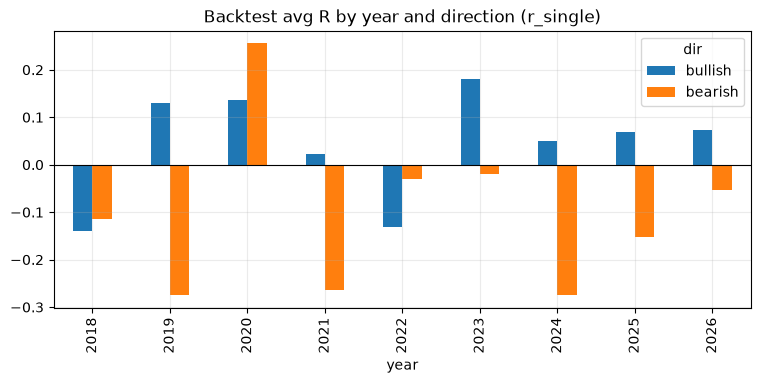

In [13]:
bt = px[px.r_single.notna()].copy(); bt["year"] = bt.date.dt.year; bt["dir"] = bt.direction.map({1:"bullish",-1:"bearish"})
def by_year(df):
    rows=[]
    for (y,d),g in df.groupby(["year","dir"]):
        rows.append((y,d,len(g),g.r_single.mean()))
    return pd.DataFrame(rows,columns=["year","dir","n","avgR"]).pivot(index="year",columns="dir",values="avgR")
by = by_year(bt); by["all"] = bt.groupby("year").r_single.mean(); by["n"] = bt.groupby("year").size()
print(by.to_string()); print("\nOverall:", bt.groupby("dir").r_single.mean().round(3).to_dict(), "all=%.3f" % bt.r_single.mean())
by[["bullish","bearish"]].plot.bar(title="Backtest avg R by year and direction (r_single)"); plt.axhline(0,c="k",lw=.8); plt.show()

In [14]:
# Direction-aware scores: higher = hypothesised BETTER (the "do not chase extended breakouts" family).
bt["risk_pct"] = 2 * bt.atr_pct                                   # stop = 2 x ATR, so stop% = 2 x ATR%
bt["ext_52w"]   = -(bt.pct_from_52w_high * bt.direction)         # further from the 52w extreme in trade direction
bt["ext_sma50"] = -(bt.dist_sma50_pct * bt.direction)
bt["ext_ret20"] = -(bt.ret_20d * bt.direction)
bt["tight_chan"] = -bt.chan_squeeze_pctile
bt["low_atr"]   = -bt.atr_pct
bt["wide_stop"] = bt.risk_pct                                     # the LIVE finding: wider stop did better
bt["liquid"]    = bt.log_dollar_vol_20
FEATS = ["ext_52w","ext_sma50","ext_ret20","tight_chan","low_atr","wide_stop","liquid"]
def quint(df, col, q=5):
    d = df.dropna(subset=[col]).copy()
    d["q"] = d.groupby("direction")[col].transform(lambda s: pd.qcut(s.rank(method="first"), q, labels=False))
    return d
rows = []
for col in FEATS:
    d = quint(bt, col)
    t_ = d.groupby(["direction","q"]).r_single.mean().unstack()
    for dirn in (-1, 1): rows.append({"feature": col, "dir": dirn, **{f"Q{int(q)+1}": v for q, v in t_.loc[dirn].items()}})
Q = pd.DataFrame(rows).set_index(["feature","dir"]); Q["Q5-Q1"] = Q.Q5 - Q.Q1
print("Backtest avg R by quintile (Q1 = lowest score ... Q5 = highest = hypothesised best), within direction"); print(Q.round(3).to_string())

Backtest avg R by quintile (Q1 = lowest score ... Q5 = highest = hypothesised best), within direction
                   Q1     Q2     Q3     Q4     Q5  Q5-Q1
feature    dir                                          
ext_52w    -1  -0.112 -0.102 -0.098 -0.086 -0.072  0.040
            1   0.014  0.034  0.089  0.066  0.066  0.052
ext_sma50  -1  -0.125 -0.091 -0.110 -0.094 -0.046  0.079
            1   0.029  0.019  0.032  0.065  0.125  0.096
ext_ret20  -1  -0.108 -0.095 -0.118 -0.092 -0.052  0.056
            1   0.042  0.016  0.040  0.054  0.119  0.078
tight_chan -1  -0.088 -0.121 -0.111 -0.092 -0.053  0.034
            1   0.021  0.016  0.057  0.084  0.093  0.072
low_atr    -1  -0.148 -0.084 -0.109 -0.099 -0.026  0.121
            1   0.082  0.055  0.042  0.021  0.070 -0.012
wide_stop  -1  -0.026 -0.099 -0.109 -0.084 -0.148 -0.121
            1   0.070  0.021  0.042  0.055  0.082  0.012
liquid     -1  -0.058 -0.066 -0.092 -0.098 -0.152 -0.094
            1   0.049  0.022  0.045  0.041 

In [15]:
# year-by-year stability of the top-minus-bottom quintile spread (computed within each direction, then averaged)
def stab(col):
    out = {}
    for y, g in bt.groupby("year"):
        d = quint(g, col); t_ = d.groupby(["direction","q"]).r_single.mean().unstack()
        out[y] = (t_[4] - t_[0]).mean()
    return pd.Series(out)
S = pd.DataFrame({c: stab(c) for c in FEATS})
print("Q5-Q1 spread by year (positive = hypothesis held that year)"); print(S.round(3).to_string())
print("\
years positive (of %d):" % len(S)); print((S>0).sum().to_string())
print("\
mean yearly spread:"); print(S.mean().round(3).to_string())

Q5-Q1 spread by year (positive = hypothesis held that year)
      ext_52w  ext_sma50  ext_ret20  tight_chan  low_atr  wide_stop  liquid
2018    0.305      0.268      0.277       0.341    0.300     -0.300  -0.188
2019   -0.132      0.081      0.084       0.077   -0.153      0.153   0.040
2020    0.365      0.138      0.225      -0.313    0.416     -0.416  -0.090
2021   -0.166      0.024      0.036       0.093   -0.057      0.057   0.021
2022    0.176      0.465      0.162       0.321    0.042     -0.042  -0.081
2023    0.053      0.164      0.047      -0.059    0.011     -0.011  -0.052
2024   -0.112      0.015      0.063       0.150    0.024     -0.024   0.112
2025    0.066     -0.054     -0.049       0.016   -0.111      0.111   0.068
2026    0.072      0.205      0.225       0.193    0.243     -0.243  -0.044
years positive (of 9):
ext_52w       6
ext_sma50     8
ext_ret20     8
tight_chan    7
low_atr       6
wide_stop     3
liquid        4
mean yearly spread:
ext_52w       0.070
ext_s

**Replication of the live "wide stop wins" cut.** In the live ledger a stop distance above 11% of price averages +0.4 R. The table above shows whether the 9-year backtest has the same gradient in `risk_pct` (2×ATR%). If the gradient is flat or inconsistent across years, the live result is a 3-week regime effect or a censoring artefact, not a durable property.

## 6. Features at signal time → live outcome (the part of the ledger that has research capture)

In [16]:
C = pd.read_csv(D + "candidate_observation.csv", parse_dates=["session_date"])
for _c in ["triggered", "passed_guard", "tracked_intent"]: C[_c] = C[_c].map({"t": True, "f": False})
F = pd.read_csv(D + "feature_snapshot.csv", parse_dates=["session_date"])
F = pd.concat([F.drop(columns="features"), pd.json_normalize(F.features.apply(json.loads))], axis=1)
Lx = L.merge(C[["id","session_rank","combined_score","alignment_score","breakout_dist_atr","distance_to_channel_pct","passed_guard"]].rename(columns={"id":"observation_id"}), on="observation_id", how="left")
Lx = Lx.merge(F[["id","pct_from_52w_high","dist_sma50_pct","ret_20d","ret_5d","atr_pct","vol_ratio_50","chan_squeeze_pctile","log_dollar_vol_20","close_location"]].rename(columns={"id":"feature_snapshot_id"}), on="feature_snapshot_id", how="left")
Rx = Lx[Lx.res & Lx.pct_from_52w_high.notna()].copy()
print("ledger rows with captured features:", Lx.pct_from_52w_high.notna().sum(), "| resolved among them:", len(Rx))
for col in ["pct_from_52w_high","dist_sma50_pct","ret_20d","atr_pct","vol_ratio_50","chan_squeeze_pctile","log_dollar_vol_20","session_rank","combined_score","breakout_dist_atr"]:
    d = Rx.dropna(subset=[col]).copy()
    d["q"] = d.groupby("direction")[col].transform(lambda s: pd.qcut(s.rank(method="first"), 4, labels=["q1","q2","q3","q4"]))
    print(f"\n{col}:"); print(d.pivot_table(index="direction", columns="q", values="outcome_r", aggfunc="mean").round(3).to_string())

ledger rows with captured features: 1329 | resolved among them: 308

pct_from_52w_high:
q            q1    q2    q3     q4
direction                         
-1        0.737 0.263 0.158 -0.368
 1        0.487 0.718 0.744  0.385

dist_sma50_pct:
q            q1    q2    q3     q4
direction                         
-1        0.368 0.263 0.211 -0.053
 1        0.744 0.641 0.692  0.256

ret_20d:
q            q1    q2    q3    q4
direction                        
-1        0.211 0.000 0.368 0.211
 1        0.641 0.590 0.641 0.462

atr_pct:
q             q1    q2    q3    q4
direction                         
-1        -0.316 0.105 0.526 0.474
 1         0.795 0.538 0.692 0.308

vol_ratio_50:
q            q1    q2    q3    q4
direction                        
-1        0.421 0.263 0.105 0.000
 1        0.744 0.590 0.667 0.333

chan_squeeze_pctile:
q            q1    q2    q3     q4
direction                         
-1        0.526 0.368 0.000 -0.105
 1        0.641 0.538 0.821  0.333

log_d

## 7. Forward return labels (`fwd_v1`) — what happens to *every* triggered candidate, not just the ledger's
These are fixed-horizon returns from the signal-day close and are independent of the stop/target mechanics, so they are free of the exit-rule and resolution-time bias.

In [17]:
FL = pd.read_csv(D + "forward_return_label.csv", parse_dates=["t0_session"])
FL = FL[FL.label_status=="final"]
FL["dir"] = FL.direction.map({1:"bullish",-1:"bearish"})
g = FL.groupby(["horizon_sessions","dir"]).agg(n=("directional_return","size"), dir_ret_pct=("directional_return", lambda s: s.mean()*100),
        dir_excess_pct=("directional_excess_return", lambda s: s.mean()*100), hit_rate=("directional_return", lambda s: (s>0).mean()*100),
        mfe_pct=("mfe", lambda s: s.mean()*100), mae_pct=("mae", lambda s: s.mean()*100))
print(g.round(3).to_string())
print("\nlabels by t0 session:", FL.groupby("t0_session").size().to_dict())

                             n  dir_ret_pct  dir_excess_pct  hit_rate  mfe_pct  mae_pct
horizon_sessions dir                                                                   
1                bearish  6676        0.074          -0.032    47.184    2.136   -2.076
                 bullish  4743        0.193           0.424    53.595    1.607   -1.222
3                bearish  4749        1.407           0.477    55.127    4.427   -2.916
                 bullish  3332        0.675           1.585    62.485    3.058   -2.296
5                bearish  2830        1.952           0.424    52.332    5.849   -3.371
                 bullish  1881        0.707           2.227    61.404    4.086   -3.260

labels by t0 session: {Timestamp('2026-10-09 00:00:00'): 4379, Timestamp('2026-10-12 00:00:00'): 4695, Timestamp('2026-10-13 00:00:00'): 5071, Timestamp('2026-10-14 00:00:00'): 3826, Timestamp('2026-10-15 00:00:00'): 2909, Timestamp('2026-10-16 00:00:00'): 1698, Timestamp('2026-10-19 00:00:00')

In [18]:
# cluster bootstrap on the 3-session label (days = clusters)
for h in [1,3,5]:
    d = FL[FL.horizon_sessions==h].assign(x=lambda d: d.directional_excess_return*100)
    for dirn,gg in d.groupby("dir"):
        m,lo,hi,n = boot_mean(gg, col="x", cluster="t0_session")
        print(f"h={h} {dirn:8s} directional excess return: {m:+.2f}% [{lo:+.2f}, {hi:+.2f}] n={n}  (days={gg.t0_session.nunique()})")

h=1 bearish  directional excess return: -0.03% [-0.76, +0.66] n=6676  (days=7)
h=1 bullish  directional excess return: +0.42% [-0.05, +0.80] n=4743  (days=7)
h=3 bearish  directional excess return: +0.48% [+0.27, +0.81] n=4749  (days=5)
h=3 bullish  directional excess return: +1.58% [+1.12, +2.00] n=3332  (days=5)
h=5 bearish  directional excess return: +0.42% [-0.51, +2.00] n=2830  (days=3)
h=5 bullish  directional excess return: +2.23% [+1.87, +2.63] n=1881  (days=3)


## 8. Forward paper tracker — five exit policies on the same signals, with costs
Entries at the next open; R is measured against the *actual* initial risk of each variant; net R is printed at 0 / 10 / 25 bps round-trip.

In [19]:
PE = pd.read_csv(D + "paper_event.csv"); PO = pd.read_csv(D + "paper_observation.csv"); V = pd.read_csv(D + "strategy_variant.csv")
V["short"] = V.variant_key.str.replace("donchian_breakout__exit_", "")
cl = PE[PE.event_type=="closed"].copy()
pl = cl.payload.apply(json.loads)
cl["reason"] = pl.apply(lambda p: p.get("reason")); cl["bars"] = pl.apply(lambda p: p.get("bars_held"))
for bps in ["0","10","25"]: cl["net"+bps] = pl.apply(lambda p, b=bps: p["r_net_actual"][b])
cl["risk_atr"] = pl.apply(lambda p: p["initial_risk"]/p["atr"])
cl = cl.merge(PO[["id","variant_id","symbol","direction","signal_session"]].rename(columns={"id":"observation_id"}), on="observation_id").merge(V[["id","short"]].rename(columns={"id":"variant_id"}), on="variant_id")
entered = PE[PE.event_type=="entered"].merge(PO[["id","variant_id"]].rename(columns={"id":"observation_id"}), on="observation_id")
summ = cl.groupby("short").agg(closed=("net0","size"), avg_bars=("bars","mean"), r_gross=("net0","mean"), r_10bps=("net10","mean"), r_25bps=("net25","mean"), stop_exit=("reason", lambda s: (s=="stop").mean()*100), risk_in_atr=("risk_atr","median"))
summ["entered"] = entered.merge(V[["id","short"]].rename(columns={"id":"variant_id"}), on="variant_id").groupby("short").size()
summ["still_open"] = summ.entered - summ.closed
print(summ.round(3).to_string())
print("\nclose reasons:"); print(cl.groupby(["short","reason"]).size().unstack(fill_value=0).to_string())
print("\nNOTE: only trades that have already *closed* are averaged; slow trailing exits are the ones still open, so this table is censored in the same direction as the ledger.")

                                  closed  avg_bars  r_gross  r_10bps  r_25bps  stop_exit  risk_in_atr  entered  still_open
short                                                                                                                     
a_atr_stop_fixed_2r                   77     2.558   -0.645   -0.659   -0.681     89.610        2.000     1343        1266
a_atr_stop_fixed_3r                   73     2.589   -0.768   -0.781   -0.801     94.521        2.000     1343        1270
b_donchian_trail_10                   27     2.963   -0.899   -0.911   -0.930      0.000        2.418     1344        1317
c_atr_trail_3x                        23     2.870   -0.848   -0.856   -0.869      0.000        3.000     1343        1320
d_hybrid_atr_stop_to_donchian_10      69     2.536   -1.028   -1.041   -1.060    100.000        2.000     1343        1274

close reasons:
reason                            channel  stop  target  trail
short                                                       

## 9. Market context during the ledger window

BTC-USD    -1.880
CL=F        5.170
DX-Y.NYB    0.510
GC=F       -0.200
^DJI        1.970
^GSPC       0.380
^IXIC      -1.470
^RUT       -1.580
^TNX       -2.350
^VIX        7.720


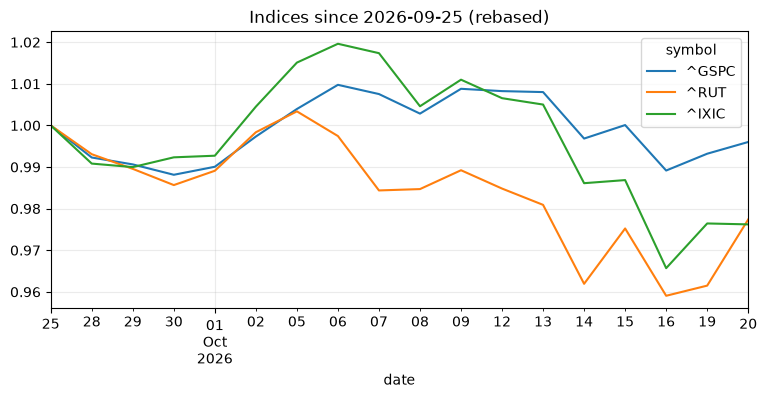

  session_date regime_state  regime_score  regime_strength  spx_ret_20  univ_ret_20
0   2026-10-12      NEUTRAL         0.060            0.060       2.457       -3.456
1   2026-10-13      NEUTRAL         0.052            0.052       2.896       -3.189
2   2026-10-14      NEUTRAL        -0.078            0.078       2.213       -3.594
3   2026-10-15      NEUTRAL         0.048            0.048       1.392       -2.532
4   2026-10-16      NEUTRAL        -0.217            0.217       0.117       -2.708
5   2026-10-19      NEUTRAL        -0.275            0.275      -0.953       -3.307
6   2026-10-20      NEUTRAL         0.041            0.041      -0.666       -2.154

Daily signal mix:
dir          bearish  bullish  bear_share%
signal_date                               
2026-09-28       434       56       88.600
2026-10-01       274       89       75.500
2026-10-02        69      100       40.800
2026-10-05        62       64       49.200
2026-10-06        55       44       55.600
2026-10-

In [20]:
IX = pd.read_csv(D + "index_prices.csv", parse_dates=["date"]).pivot(index="date", columns="symbol", values="close")
w = IX.loc["2026-09-25":]
chg = {c: (w[c].dropna().iloc[-1] / w[c].dropna().loc["2026-09-28":].iloc[0] - 1) * 100 for c in w.columns}
print(pd.Series(chg).round(2).rename("% change since 2026-09-28 (last available)").to_string())
ax = (w[["^GSPC","^RUT","^IXIC"]].dropna()/w[["^GSPC","^RUT","^IXIC"]].dropna().iloc[0]).plot(title="Indices since 2026-09-25 (rebased)"); plt.show()
MS = pd.read_csv(D + "market_snapshot.csv"); print(MS[["session_date","regime_state","regime_score","regime_strength","spx_ret_20","univ_ret_20"]].to_string())
sig_day = L.groupby(["signal_date","dir"]).size().unstack(fill_value=0); sig_day["bear_share%"] = sig_day.bearish/(sig_day.bearish+sig_day.bullish)*100
print("\nDaily signal mix:"); print(sig_day.round(1).to_string())

In [21]:
# does the daily mix of long vs short signals carry information? (breadth proxy)
dm = R.groupby(["signal_date","dir"]).outcome_r.mean().unstack()
print("Daily avg R by direction (resolved only):"); print(dm.round(2).to_string())

Daily avg R by direction (resolved only):
dir          bearish  bullish
signal_date                  
2026-09-28    -0.100   -0.240
2026-10-01     0.020   -0.230
2026-10-02     0.040   -0.520
2026-10-05     0.300   -0.160
2026-10-06     0.370   -0.390
2026-10-07     0.300    0.050
2026-10-08     0.700    0.690
2026-10-09     0.040    0.400
2026-10-12     0.680    0.650
2026-10-13     0.300    0.520
2026-10-14    -0.120    0.880
2026-10-15    -1.000    0.790
2026-10-16    -0.560    1.000
2026-10-19     0.000    0.000


## 10. The funnel: from universe to ledger

In [22]:
C["kind"] = C.signal_type.fillna("none")
f = C.groupby("session_date").agg(candidates=("id","size"), triggered=("triggered","sum"), guard_rejected=("passed_guard", lambda s: (~s).sum()))
print(f.to_string())
print("\nsignal types:", C.kind.value_counts().to_dict(), "| ML status:", C.ml_status.value_counts().to_dict())
tg = C[C.triggered]
print("\ntriggered grade mix:", tg.quality_grade.value_counts(normalize=True).round(3).to_dict())
gr = C.guard_reasons.dropna().str.strip("{}").str.split(",").explode().str.strip('"').value_counts()
print("\nguard reasons:"); print(gr.head(10).to_string())
print("\nTriggered but not in the ledger (by session):")
inl = set(L.observation_id.dropna().astype(int))
print(tg.assign(in_ledger=tg.id.isin(inl)).groupby("session_date").in_ledger.agg(["size","sum"]).to_string())

              candidates  triggered  guard_rejected
session_date                                       
2026-10-09          1460        250              80
2026-10-12          1566        359              87
2026-10-13          1692        474              90
2026-10-14          1915        669             101
2026-10-15          1456        486              70
2026-10-16          1700        499              92
2026-10-19          1635        313             103
2026-10-20          1606        366              99

signal types: {'near_bearish': 5156, 'near_bullish': 4458, 'bearish_breakout': 2065, 'bullish_breakout': 1351} | ML status: {'not_processed': 13030}

triggered grade mix: {'A': 0.706, 'C': 0.246, 'B': 0.026, 'D': 0.023}

guard reasons:
guard_reasons
illiquid_dollar_volume    667
price_discontinuity        46
insufficient_history       22

Triggered but not in the ledger (by session):
              size  sum
session_date           
2026-10-09     250  109
2026-10-12     359  

In [23]:
# why is the ledger smaller than the triggered set? (open-position slot dedupe + guard)
miss = tg[~tg.id.isin(inl)].copy()
sl = L[["symbol","signal_date","resolved_date"]]
def slot_busy(r):
    x = sl[(sl.symbol==r.symbol) & (sl.signal_date < r.session_date) & (sl.resolved_date.isna() | (sl.resolved_date >= r.session_date))]
    return len(x) > 0
miss["slot_busy"] = miss.apply(slot_busy, axis=1)
print("triggered but not in ledger:", len(miss), "| symbol already had an open ledger position:", f"{miss.slot_busy.mean():.0%}", "| guard-rejected:", f"{(~miss.passed_guard).mean():.0%}")
print("-> the ledger is a de-duplicated, guard-passed subset. The PAPER tracker registers every triggered candidate (669 x 5 variants on 10-14).")
m_ = L.merge(C[["id","quality_grade"]].rename(columns={"id":"observation_id","quality_grade":"capture_grade"}), on="observation_id")
print("\
ledger.quality_grade (rows) vs candidate_observation.quality_grade (cols) for the SAME signal:")
print(pd.crosstab(m_.quality_grade, m_.capture_grade).to_string())

triggered but not in ledger: 2057 | symbol already had an open ledger position: 94% | guard-rejected: 7%
-> the ledger is a de-duplicated, guard-passed subset. The PAPER tracker registers every triggered candidate (669 x 5 variants on 10-14).
ledger.quality_grade (rows) vs candidate_observation.quality_grade (cols) for the SAME signal:
capture_grade    A   B    C   D
quality_grade                  
A              177   1  107   1
B              149   2   85   0
C              120   1   75   2
D              157   2   66   2
F              278  18  100  16


## 11. Can a parameter-free "don't chase" rank turn the backtest positive?  (cost-adjusted, by year)
No fitting: the score is the equal-weight average of within-day, within-direction percentile ranks of five features declared in advance (`ext_sma50`, `ext_ret20`, `ext_52w`, `tight_chan`, `low_atr`). We then take the top slice of each day's signals. 7 related candidates were already tried in the Lab, so treat any positive result as a hypothesis for the forward tracker, not a finding.

In [24]:
sc = bt.dropna(subset=["ext_sma50","ext_ret20","ext_52w","tight_chan","low_atr","risk_pct"]).copy()
for c in ["ext_sma50","ext_ret20","ext_52w","tight_chan","low_atr"]:
    sc[c+"_p"] = sc.groupby(["date","direction"])[c].rank(pct=True)
sc["score"] = sc[[c+"_p" for c in ["ext_sma50","ext_ret20","ext_52w","tight_chan","low_atr"]]].mean(axis=1)
sc["day_rank"] = sc.groupby(["date","direction"]).score.rank(pct=True, ascending=False)     # 0..1, small = best
sc["cost_R"] = 0.10 / sc.risk_pct                                                                # 10 bps round-trip, in R (risk_pct is in %)
sc["net_R"] = sc.r_single - sc.cost_R
rows = []
for name, mask in [("all signals", sc.day_rank <= 1), ("top 50%", sc.day_rank <= .5), ("top 20%", sc.day_rank <= .2), ("top 10%", sc.day_rank <= .1), ("bottom 20%", sc.day_rank > .8)]:
    for dn, g in [("both", sc[mask])] + [(k, v) for k, v in sc[mask].groupby("dir")]:
        rows.append({"slice": name, "dir": dn, "n": len(g), "gross_R": g.r_single.mean(), "net_R_10bps": g.net_R.mean(), "pos_years": int((g.groupby("year").net_R.mean() > 0).sum()), "years": g.year.nunique()})
print(pd.DataFrame(rows).set_index(["slice","dir"]).round(3).to_string())

                          n  gross_R  net_R_10bps  pos_years  years
slice       dir                                                    
all signals both     590201   -0.012       -0.029          3      9
            bearish  260842   -0.094       -0.109          1      9
            bullish  329359    0.054        0.035          7      9
top 50%     both     293997   -0.009       -0.030          3      9
            bearish  129887   -0.105       -0.124          1      9
            bullish  164110    0.067        0.045          7      9
top 20%     both     116259   -0.001       -0.025          4      9
            bearish   51282   -0.105       -0.127          2      9
            bullish   64977    0.080        0.056          6      9
top 10%     both      57021    0.010       -0.015          4      9
            bearish   25106   -0.093       -0.117          2      9
            bullish   31915    0.091        0.066          7      9
bottom 20%  both     119824   -0.010       -0.02

Top-20% slice, net of 10 bps, by year:
dir   bearish  bullish   both      n
year                                
2018   -0.061   -0.118 -0.088  10672
2019   -0.436    0.203  0.010  10913
2020    0.162    0.106  0.130  12269
2021   -0.394    0.090 -0.092  12321
2022    0.011   -0.107 -0.041  14460
2023   -0.091    0.153  0.046  14939
2024   -0.353    0.050 -0.125  13919
2025   -0.137   -0.001 -0.063  14771
2026   -0.037    0.034  0.003  11995

Out-of-time (2024-2026) top-20%: net R -0.065, n=40685  | all signals same period: -0.055


Per-day capacity of the top-20% slice: median 44 trades/day


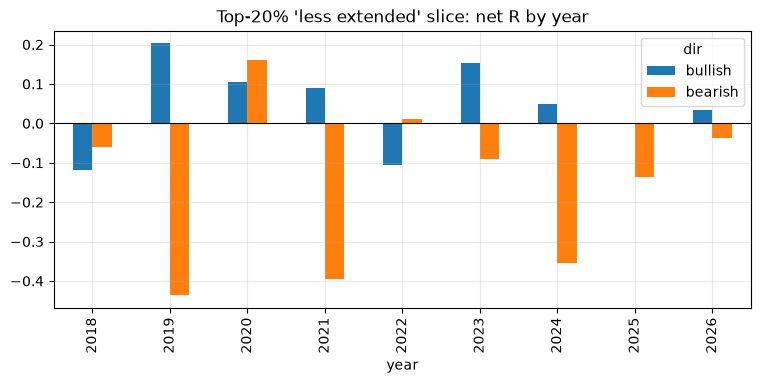

In [25]:
top = sc[sc.day_rank <= .2]
y = top.groupby(["year","dir"]).net_R.mean().unstack(); y["both"] = top.groupby("year").net_R.mean(); y["n"] = top.groupby("year").size()
print("Top-20% slice, net of 10 bps, by year:"); print(y.round(3).to_string())
oos = top[top.year >= 2024]; print("\nOut-of-time (2024-2026) top-20%%: net R %.3f, n=%d  | all signals same period: %.3f" % (oos.net_R.mean(), len(oos), sc[sc.year>=2024].net_R.mean()))
mm = [ (g.net_R.mean()) for _, g in top.groupby("date") ]
print("Per-day capacity of the top-20%% slice: median %d trades/day" % top.groupby("date").size().median())
y[["bullish","bearish"]].plot.bar(title="Top-20% 'less extended' slice: net R by year"); plt.axhline(0, c="k", lw=.8); plt.show()

**How to read it.** Positive net R only in the bullish half and only in some years would mean "a filter that avoids the worst chases", not a money machine. The honest test is the forward paper tracker (it already records every triggered candidate with the features needed to apply this score).

## 12. Summary of what the data does and does not say
(Numbers printed above are the source; this cell restates the structure for the reader.)

In [26]:
m, lo, hi, n = boot_mean(R)
print(f"""
LEDGER   {len(L):,} signals / {len(R):,} resolved / {(L.status=='open').sum():,} open over {L.signal_date.nunique()} sessions
         avg R {m:+.3f}  95% cluster CI [{lo:+.3f}, {hi:+.3f}]   -> consistent with zero
BACKTEST {len(bt):,} matured breakouts; avg R {bt.r_single.mean():+.3f}; bullish {bt[bt.direction==1].r_single.mean():+.3f}, bearish {bt[bt.direction==-1].r_single.mean():+.3f}
LABELS   {len(FL):,} final forward labels across {FL.t0_session.nunique()} sessions (too short for conclusions)
PAPER    {len(cl):,} closed positions / {len(entered):,} entered across 5 exit policies
""")


LEDGER   2,864 signals / 1,408 resolved / 1,456 open over 15 sessions
         avg R +0.064  95% cluster CI [-0.064, +0.319]   -> consistent with zero
BACKTEST 595,541 matured breakouts; avg R -0.011; bullish +0.054, bearish -0.093
LABELS   24,211 final forward labels across 7 sessions (too short for conclusions)
PAPER    269 closed positions / 6,716 entered across 5 exit policies



## 13. Findings (as of the 2026-10-21 pull)

1. **The headline ledger result (+0.064 R) is upward-biased by censoring.** Following the *same* 1,247 oldest signals, R locked in drifts from 0.00 (k=3) to −0.09 (k=10) as the slow trades resolve; at k=10, 39% are still open. Wins resolve early, losses late. The honest present estimate is ≈ −0.1 R with wide uncertainty (only 5 daily cohorts are old enough).
2. **Shorts are the weak side everywhere except the first 3 weeks of live data.** Backtest bearish: −0.094 R gross, positive in 1 of 9 years. The live bearish +0.079 R comes from early-resolving cohorts. The bullish side is the only tentatively positive one (+0.054 R gross, +0.035 net of 10 bps, positive in 7 of 9 years) — small and still within noise.
3. **"Wide stop / cheap stock / grade F wins" does NOT replicate** in the 9-year backtest (wide-stop spread −0.079 R, positive in 3 of 9 years; opposite sign to the live cut). Treat it as a 3-week artefact of who resolves first.
4. **"Don't chase extended breakouts" is the one stable pattern** (extension vs SMA50 / 20-day return positive in 8 of 9 years, mean spread +0.12–0.15 R), but as a parameter-free rank it does not turn the backtest net-positive (top 20%: −0.025 net; shorts remain negative). It is a risk-avoidance filter, not an edge.
5. **Two different "quality grades" exist.** The ledger's A–F grade and the candidate capture's A–D grade are different scales and disagree on the same signal (ledger F ↔ capture A in 278 of 412 cases). Any grade-based claim must name which one.
6. **Data coverage is short, not wrong.** Capture: 8 sessions; forward labels: 7 sessions; paper tracker: 5 sessions (tracker numbers so far are only the fastest stop-outs). The ledger is a de-duplicated subset (94% of triggered candidates missing from it already had an open position).
7. **Engine parity (live evaluator vs offline simulator) cannot be checked until ~2026-10-26**, when the first live signals reach 20 bars in the backtest dataset. 64 live signals were not flagged by the offline detector — worth explaining then.